In [6]:
%run ../Preprocessing/Preprocessing.ipynb

--------------PREPROCESSING:  ORIGINAL --------------
Model:  Mean 
Mean Absolute Error:  18.63375593247658 
Root Mean Squared Error:  36.28115976186805 
R2 Score:  -1.1709098975511416 


Model:  Median 
Mean Absolute Error:  12.87178038095238 
Root Mean Squared Error:  36.15577891714317 
R2 Score:  -0.20736138031842005 


Model:  Linear Regression 
Mean Absolute Error:  20.00335016956664 
Root Mean Squared Error:  38.36786158123488 
R2 Score:  -2.5678116056931772 


Model:  Ridge 
Mean Absolute Error:  19.137750299836156 
Root Mean Squared Error:  37.13623395540704 
R2 Score:  -1.6136422570948683 


Model:  KNN n = 3 
Mean Absolute Error:  24.32450196825397 
Root Mean Squared Error:  58.785985729659785 
R2 Score:  -20.719728187599735 


Model:  KNN n = 7 
Mean Absolute Error:  21.065392000000003 
Root Mean Squared Error:  46.64236771339844 
R2 Score:  -7.27391074964352 


Model:  KNN n = 21 
Mean Absolute Error:  19.851838875283452 
Root Mean Squared Error:  40.884996252410325 
R2 Sco

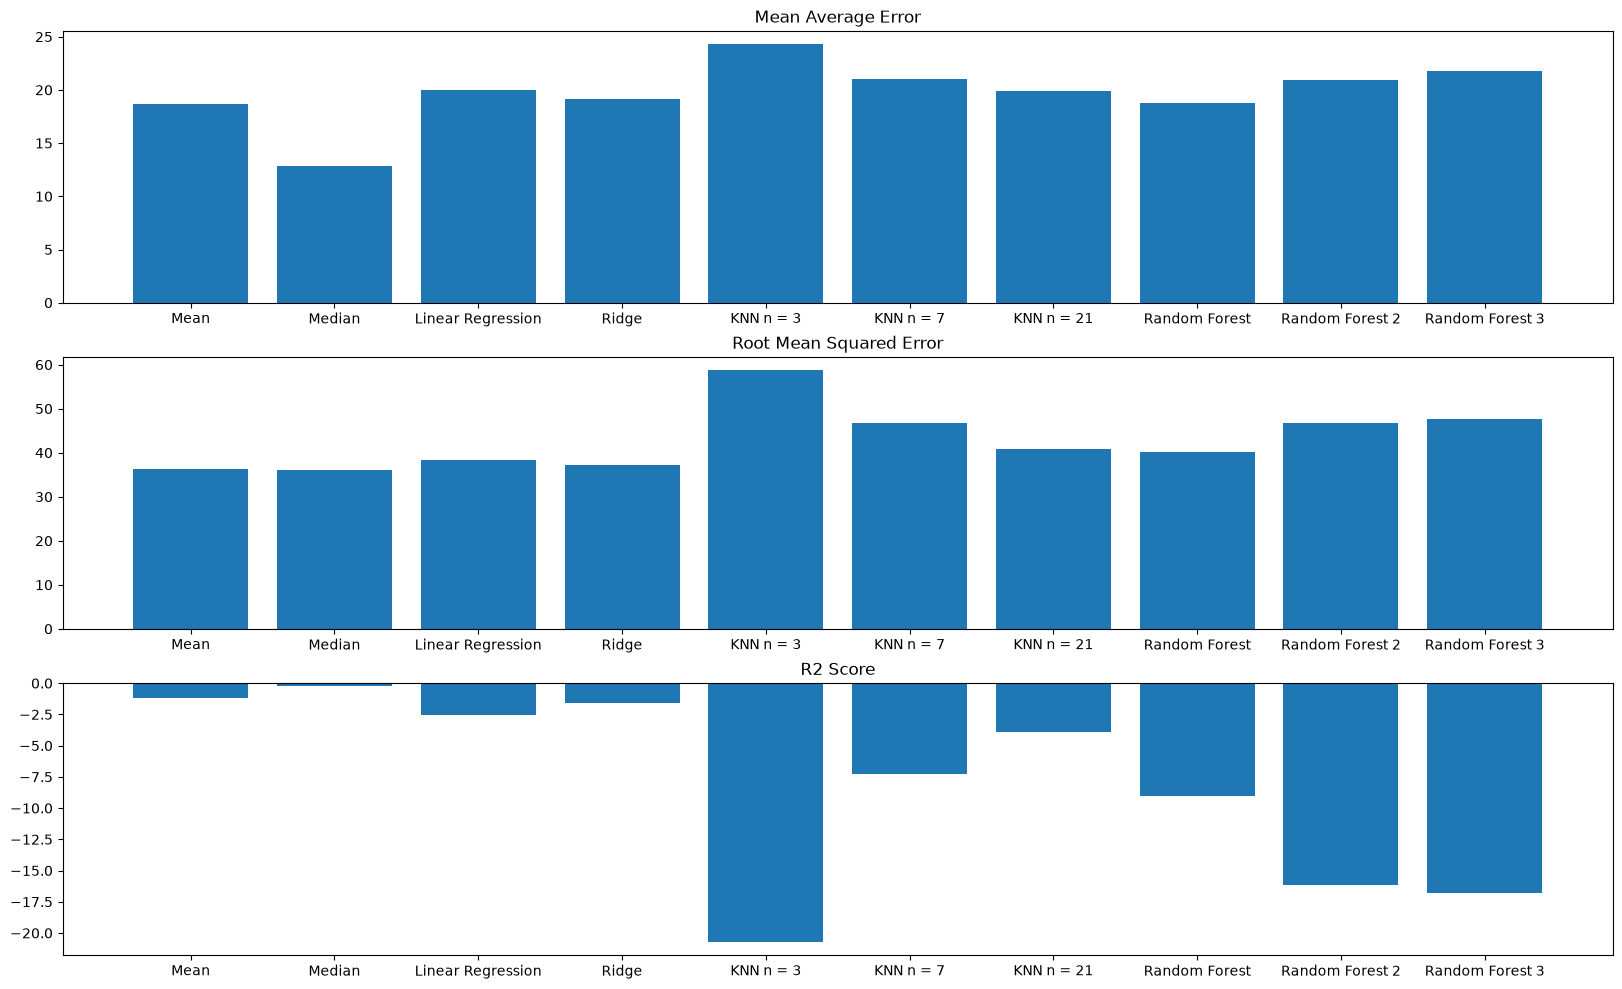

--------------PREPROCESSING:  ALL --------------
Model:  Mean 
Mean Absolute Error:  18.63375593247658 
Root Mean Squared Error:  36.28115976186805 
R2 Score:  -1.1709098975511416 


Model:  Median 
Mean Absolute Error:  12.87178038095238 
Root Mean Squared Error:  36.15577891714317 
R2 Score:  -0.20736138031842005 


Model:  Linear Regression 
Mean Absolute Error:  20.274450255578518 
Root Mean Squared Error:  38.67035391791728 
R2 Score:  -2.814529412924028 


Model:  Ridge 
Mean Absolute Error:  19.1579642727436 
Root Mean Squared Error:  37.16738731823166 
R2 Score:  -1.6383800288621537 


Model:  KNN n = 3 
Mean Absolute Error:  23.329193841269845 
Root Mean Squared Error:  56.22574373314476 
R2 Score:  -17.931048941274756 


Model:  KNN n = 7 
Mean Absolute Error:  20.686677496598644 
Root Mean Squared Error:  46.414582135144364 
R2 Score:  -7.640931274185327 


Model:  KNN n = 21 
Mean Absolute Error:  19.34700716553288 
Root Mean Squared Error:  40.409565751631554 
R2 Score:  -

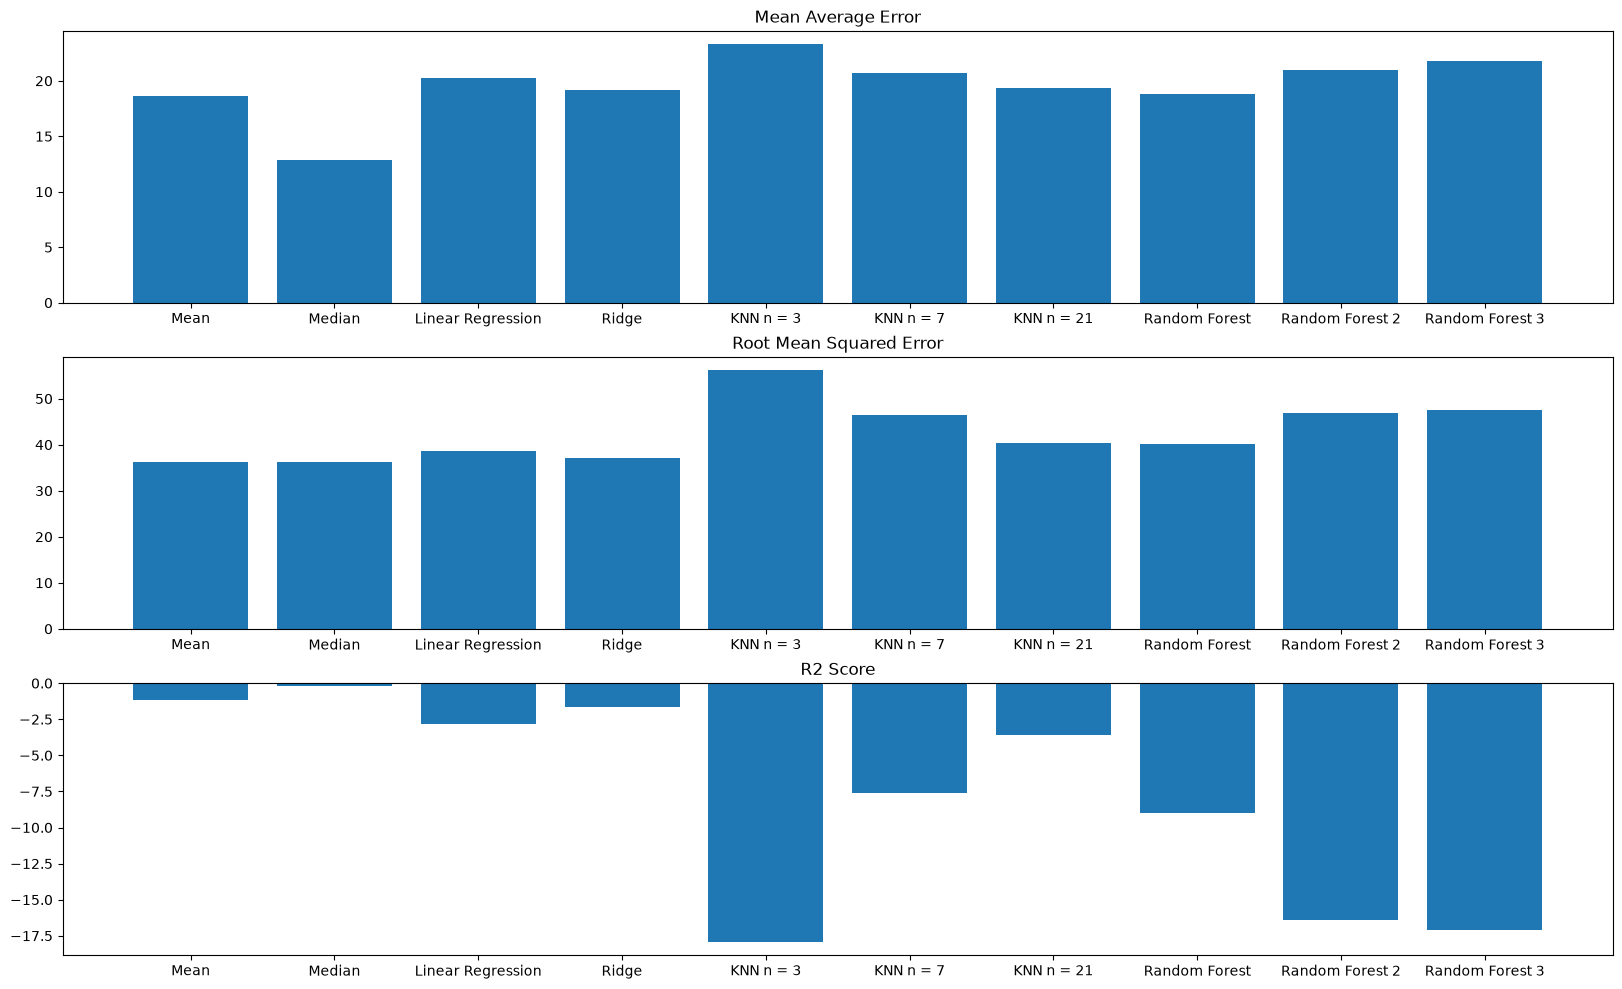

--------------PREPROCESSING:  FIRE WEATHER INDEX ONLY --------------
Model:  Mean 
Mean Absolute Error:  18.63375593247658 
Root Mean Squared Error:  36.28115976186805 
R2 Score:  -1.1709098975511416 


Model:  Median 
Mean Absolute Error:  12.87178038095238 
Root Mean Squared Error:  36.15577891714317 
R2 Score:  -0.20736138031842005 


Model:  Linear Regression 
Mean Absolute Error:  19.142287039658342 
Root Mean Squared Error:  36.94410661901439 
R2 Score:  -1.5303474300499316 


Model:  Ridge 
Mean Absolute Error:  18.832313424651467 
Root Mean Squared Error:  36.57030112356057 
R2 Score:  -1.330597649584073 


Model:  KNN n = 3 
Mean Absolute Error:  20.47176882539682 
Root Mean Squared Error:  49.231835043114344 
R2 Score:  -11.05324756548622 


Model:  KNN n = 7 
Mean Absolute Error:  20.64644288435374 
Root Mean Squared Error:  45.60540102545287 
R2 Score:  -8.051703487776262 


Model:  KNN n = 21 
Mean Absolute Error:  20.31126907936508 
Root Mean Squared Error:  42.2293172637

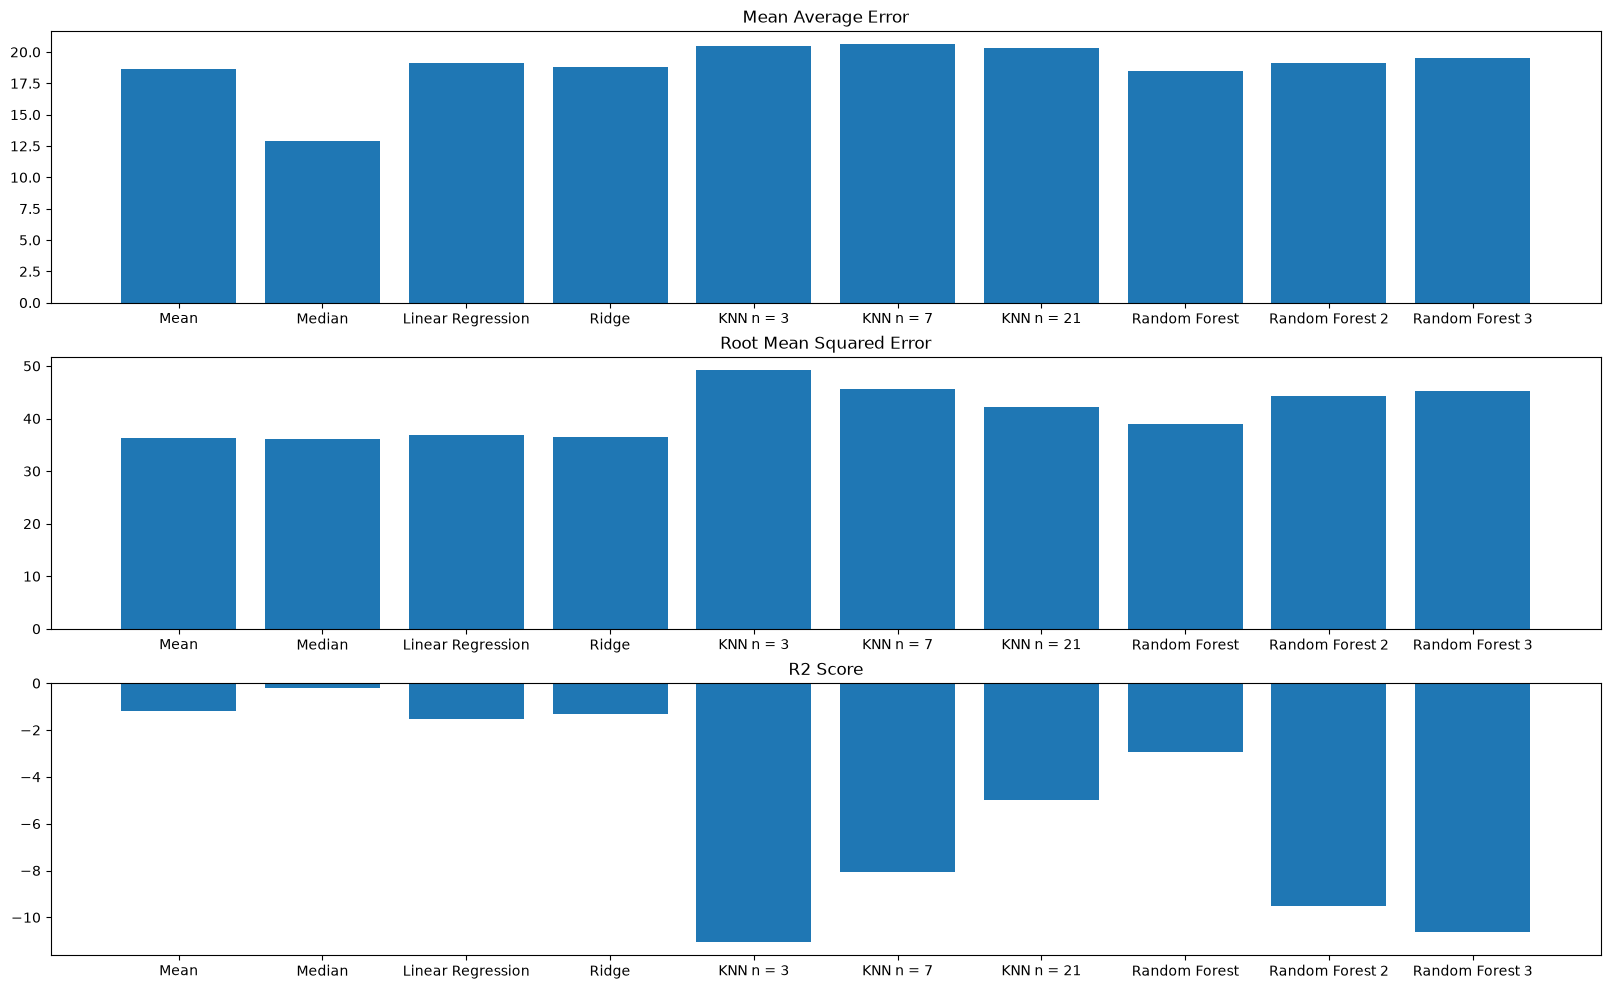

--------------PREPROCESSING:  VERY PRUNED (TEST) --------------
Model:  Mean 
Mean Absolute Error:  18.63375593247658 
Root Mean Squared Error:  36.28115976186805 
R2 Score:  -1.1709098975511416 


Model:  Median 
Mean Absolute Error:  12.87178038095238 
Root Mean Squared Error:  36.15577891714317 
R2 Score:  -0.20736138031842005 


Model:  Linear Regression 
Mean Absolute Error:  19.757461847154573 
Root Mean Squared Error:  38.12471963556181 
R2 Score:  -2.443078033716937 


Model:  Ridge 
Mean Absolute Error:  19.046022382204914 
Root Mean Squared Error:  37.07721426059284 
R2 Score:  -1.5781260683602656 


Model:  KNN n = 3 
Mean Absolute Error:  24.78640596825397 
Root Mean Squared Error:  60.47897806540046 
R2 Score:  -23.60237624250488 


Model:  KNN n = 7 
Mean Absolute Error:  22.462460789115642 
Root Mean Squared Error:  49.02460967047188 
R2 Score:  -8.690795878776816 


Model:  KNN n = 21 
Mean Absolute Error:  20.45804903401361 
Root Mean Squared Error:  41.78855295588076 

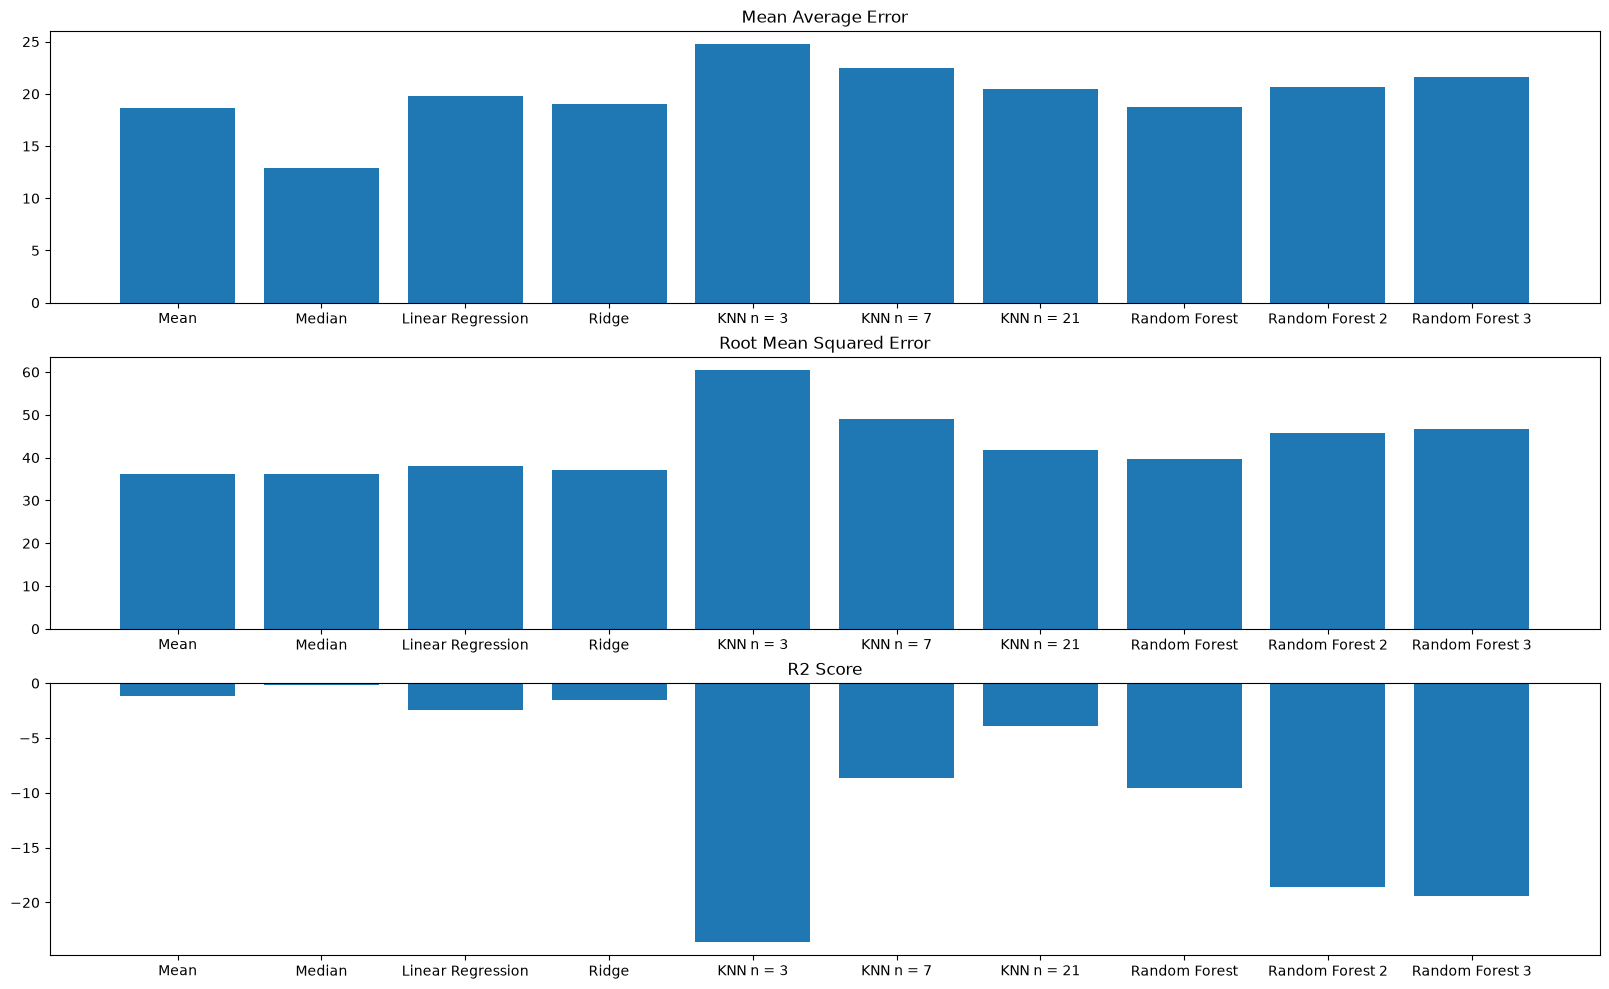

In [4]:
from sklearn.model_selection import cross_validate, RepeatedKFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
#Split the data
X = df[categorical_columns + numerical_columns]
y = df["area"]

# Trying Different Models and preprocessing pipelines using cross validation

cv = RepeatedKFold(n_splits=25, n_repeats=5, random_state=RANDOM_STATE)

for title, preprocessing in preprocessing_pipelines.items():
    print("--------------PREPROCESSING: ", title,"--------------")

    resultsMAE =[]
    resultsRMSE = []
    resultsR2 = []
    #Run all of the models and print out their results
    for name, model in models.items():
        model = make_pipeline(
            preprocessing, 
            model
        )
        results = cross_validate(
            model, X, y, 
            cv=cv,
            scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2":"r2"},
            return_train_score=False
        )

        mae = -results["test_mae"].mean()
        rmse = -results["test_rmse"].mean()
        r2 = results["test_r2"].mean()
    
        resultsMAE.append(mae)
        resultsRMSE.append(rmse)
        resultsR2.append(r2)
    
        print("Model: ", name ,"\nMean Absolute Error: ", mae, "\nRoot Mean Squared Error: ", rmse,"\nR2 Score: ", r2 ,"\n\n")

    #Plot Results
    plt.figure(figsize={len(models.keys()) * 2,12}) #Figure is dynamically sized to allow for more models to be added as needed
    
    plt.subplot(311, title="Mean Average Error").bar(range(len(resultsMAE)),resultsMAE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(312, title="Root Mean Squared Error").bar(range(len(resultsRMSE)),resultsRMSE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(313, title="R2 Score").bar(range(len(resultsR2)),resultsR2)
    plt.xticks(range(len(models.keys())),models.keys())

    plt.show()